# UTS Graf Sains Data: Rekomendasi Produk RetailRocket dengan Neo4j

**Nama:** Nanik Erawati  
**NIM:** 23031554066  
**Periode data:** Training 09/05/2015 - 28/07/2015 | Testing 29/07/2015 - 18/08/2015

**Alur pengerjaan:** filter data (wrangling) -> impor ke graf Neo4j -> komposisi subgraph -> VSM user dan item -> pemilihan proyeksi -> similarity -> penulisan balik ke graf -> rekomendasi KNN -> evaluasi Hit@5 dan NDCG@5.

**Dataset:** RetailRocket E-commerce Dataset (Roman Zykov), file `events.csv`
(https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset).
Kolom: `timestamp` (epoch milidetik), `visitorid`, `event` (view / addtocart / transaction), `itemid`, `transactionid`.

# Pasang paket

In [9]:
%pip install pandas numpy scipy scikit-learn networkx matplotlib neo4j

# Tugas pendahuluan 1.2

**1. Apa nama database yang digunakan pada tutorial ini?**  
Database `neo4j`, sesuai argumen `database_="neo4j"` pada `execute_query`. Ini adalah database default Neo4j.

**2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat mengakses database lain dalam 1 instance!**  
- Klausa `USE namadb` di awal query Cypher (di Neo4j Browser: `:use namadb`).
- Pada driver: `driver.session(database="namadb")` atau `database_="namadb"` pada `execute_query`.
- DDL pendukung: `SHOW DATABASES`, `CREATE DATABASE namadb`, `DROP DATABASE namadb`.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**  
Graf **berarah** (directed): simpul berlabel `Person`, relasi `KNOWS` dari Arthur ke Guinevere, Lancelot, dan Merlin. Bentuknya graf bintang (*star*) dengan Arthur sebagai pusat (out-degree 3). Graf ini tidak berbobot dan homogen (satu jenis simpul dan satu jenis relasi). Karena memakai `MERGE`, menjalankan ulang tidak membuat simpul atau relasi ganda.

# Setup dan koneksi

In [1]:
import os, math
import numpy as np, pandas as pd, scipy.sparse as sp, networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from neo4j import GraphDatabase

NIM = "23031554066"
TR_S, TR_E = "2015-05-09", "2015-07-28"      # fold training (awal, akhir)
TE_S, TE_E = "2015-07-29", "2015-08-18"      # fold testing  (awal, akhir)

# lokasi events.csv (dicek berurutan, ambil yang pertama ada)
CSV_CANDIDATES = [
    os.path.join(os.getcwd(), "events.csv"),
    os.path.join(os.getcwd(), "UTS_Graf", "events.csv"),
    r"E:\Semester\Semester 7\Graf Sains Data\archive\events.csv",
]
CSV_PATH = next((p for p in CSV_CANDIDATES if os.path.isfile(p)), None)
if CSV_PATH is None:
    raise FileNotFoundError(f"events.csv tidak ditemukan. Lokasi yang dicek: {CSV_CANDIDATES}")

URI, AUTH = "bolt://127.0.0.1:7687", ("neo4j", "utsgraf1")   # GANTI password

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi Neo4j OK")

Koneksi Neo4j OK


# Demo tutorial 1.2

In [2]:
# Demo tutorial 1.2 (graf pertemanan Arthur).
# CATATAN: jalankan SEBELUM sel impor. Data Person ini akan terhapus otomatis oleh sel impor (sel 9).
def add_friend(name, friend_name):
    with driver.session(database="neo4j") as s:
        s.run("MERGE (a:Person {name: $name}) "
              "MERGE (friend:Person {name: $friend_name}) "
              "MERGE (a)-[:KNOWS]->(friend)", name=name, friend_name=friend_name).consume()

def print_friends(name):
    with driver.session(database="neo4j") as s:
        for rec in s.run("MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
                         "RETURN friend.name ORDER BY friend.name", name=name):
            print(rec["friend.name"])

for f in ["Guinevere", "Lancelot", "Merlin"]:
    add_friend("Arthur", f)
print_friends("Arthur")

Guinevere
Lancelot
Merlin


# Filter periode

Periode (kombinasi unik tiap mahasiswa, baris ke-9 pada tabel pembagian data):

| Fold | Awal | Akhir |
|---|---|---|
| Training (P1) | 09/05/2015 | 28/07/2015 |
| Testing (P2) | 29/07/2015 | 18/08/2015 |

Kolom `timestamp` bertipe **epoch milidetik**, sehingga batas tanggal dikonversi ke milidetik. Batas akhir dibuat inklusif sampai akhir hari (+86.400.000 ms). Hasil filter disimpan ke tiga file `.csv`:
`events_train.csv`, `events_test.csv`, dan `events_filtered.csv` (gabungan dengan kolom `fold`).

**Rancangan evaluasi:** hanya fold *training* yang dimasukkan ke graf. Fold *testing* dipakai sebagai kunci jawaban untuk menghitung Hit@5 dan NDCG@5, sehingga tidak ada kebocoran data.

# Filter dan simpan CSV

In [3]:
df = pd.read_csv(CSV_PATH)                # timestamp = epoch MILIDETIK
ms = lambda d: int(pd.Timestamp(d).value // 10**6)
cut = lambda a, b: df[(df.timestamp >= ms(a)) & (df.timestamp < ms(b) + 86_400_000)]

train, test = cut(TR_S, TR_E), cut(TE_S, TE_E)
train.to_csv("events_train.csv", index=False)
test.to_csv("events_test.csv", index=False)
pd.concat([train.assign(fold="train"), test.assign(fold="test")]).to_csv("events_filtered.csv", index=False)

print("Total data asli :", len(df))
print("Baris training  :", len(train))
print("Baris testing   :", len(test))
print(train.event.value_counts(), test.event.value_counts(), sep="\n\n")

Total data asli : 2756101
Baris training  : 1713293
Baris testing   : 384726
event
view           1657632
addtocart        41888
transaction      13773
Name: count, dtype: int64

event
view           371207
addtocart       10320
transaction      3199
Name: count, dtype: int64


# Impor ke Neo4j

Mekanisme impor per batch (5.000 baris) memakai `UNWIND`. Query Cypher:

```cypher
UNWIND $rows AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
```

- `UNWIND $rows AS row` mengurai satu batch menjadi baris-baris yang diproses satu per satu.
- `MERGE` membuat simpul hanya jika belum ada (tidak ganda), didukung *unique constraint* pada `visitorId` dan `itemId`.
- `CREATE` membuat relasi interaksi beserta `timestamp`. Relasi `BOUGHT` juga menyimpan `transactionId`.
- Tiga jenis event dipetakan ke tiga jenis relasi: `view` -> `VIEWED`, `addtocart` -> `ADDED_TO_CART`, `transaction` -> `BOUGHT`.

> Sel berikut **mengosongkan database** sebelum impor supaya relasi tidak ganda. Pastikan terhubung ke instance khusus RetailRocket.

# Impor

In [17]:
REL = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}

def write(session, fn, *a, **kw):         # kompatibel driver 4.x dan 5.x/6.x
    return (getattr(session, "execute_write", None) or session.write_transaction)(fn, *a, **kw)

def run(tx, q, **p):
    tx.run(q, **p).consume()

def q_import(ev):
    props = "timestamp: row.timestamp" + (", transactionId: row.transactionid" if ev == "transaction" else "")
    return f"""UNWIND $rows AS row
MERGE (v:Visitor {{visitorId: row.visitorid}})
MERGE (i:Item {{itemId: row.itemid}})
CREATE (v)-[:{REL[ev]} {{{props}}}]->(i)"""

with driver.session() as s:
    # kosongkan database sebelum impor (khusus database proyek ini)
    while s.run("MATCH (n) WITH n LIMIT 10000 DETACH DELETE n RETURN count(*) AS c").single()["c"]:
        pass

    for old, new in [
        ("CREATE CONSTRAINT visitor_id IF NOT EXISTS ON (v:Visitor) ASSERT v.visitorId IS UNIQUE",
         "CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"),
        ("CREATE CONSTRAINT item_id IF NOT EXISTS ON (i:Item) ASSERT i.itemId IS UNIQUE",
         "CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE"),
    ]:
        try:
            s.run(old).consume()           # sintaks Neo4j 4.x
        except Exception:
            s.run(new).consume()           # sintaks Neo4j 5.x

    B = 5000
    for ev in REL:
        sub = train[train.event == ev]
        cols = ["timestamp", "visitorid", "itemid"] + (["transactionid"] if ev == "transaction" else [])
        for k in range(0, len(sub), B):
            part = sub.iloc[k:k + B][cols].astype("int64")
            rows = [dict(zip(cols, r)) for r in part.to_numpy().tolist()]   # tipe python murni
            write(s, run, q_import(ev), rows=rows)
            if (k // B) % 20 == 0:
                print(f"{ev}: {min(k + B, len(sub)):,} / {len(sub):,}")
        print("selesai:", ev)

view: 5,000 / 1,657,632
view: 105,000 / 1,657,632
view: 205,000 / 1,657,632
view: 305,000 / 1,657,632
view: 405,000 / 1,657,632
view: 505,000 / 1,657,632
view: 605,000 / 1,657,632
view: 705,000 / 1,657,632
view: 805,000 / 1,657,632
view: 905,000 / 1,657,632
view: 1,005,000 / 1,657,632
view: 1,105,000 / 1,657,632
view: 1,205,000 / 1,657,632
view: 1,305,000 / 1,657,632
view: 1,405,000 / 1,657,632
view: 1,505,000 / 1,657,632
view: 1,605,000 / 1,657,632
selesai: view
addtocart: 5,000 / 41,888
selesai: addtocart
transaction: 5,000 / 13,773
selesai: transaction


# Komposisi subgraph

Dua query Cypher dijalankan lewat Python API (`driver.session().run(...)`):

```cypher
MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah ORDER BY jumlah DESC
MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC
```

**Penjelasan:**
- `MATCH (n)` mengambil semua simpul. `labels(n)[0]` mengambil label pertama tiap simpul (Visitor atau Item). `count(n)` menghitung jumlah simpul per label. Pengelompokan terjadi otomatis karena `labels(n)[0]` ikut di `RETURN`.
- `MATCH ()-[r]->()` mengambil semua relasi berarah. `type(r)` memisahkan jenis relasi dan `count(r)` menghitungnya.
- `ORDER BY jumlah DESC` mengurutkan dari yang terbanyak.

# Komposisi dan verifikasi

In [18]:
def snapshot():
    with driver.session() as s:
        n = pd.DataFrame(s.run("MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah ORDER BY jumlah DESC").data())
        r = pd.DataFrame(s.run("MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC").data())
    return n, r

nodes0, rels0 = snapshot()      # disimpan sebagai kondisi SEBELUM similarity (No. 8)
print(nodes0, "\n")
print(rels0)

# verifikasi: graf hanya berisi Visitor dan Item, dan jumlah relasi = jumlah baris training
assert set(nodes0.jenis_simpul) == {"Visitor", "Item"}, "Ada label lain (mis. Person): jalankan ulang sel impor (sel 9)."
assert int(rels0.jumlah.sum()) == len(train), "Jumlah relasi tidak sama dengan baris training: jalankan ulang sel impor (sel 9)."
print("\nVerifikasi OK: graf bersih dan lengkap.")

  jenis_simpul  jumlah
0      Visitor  872567
1         Item  191300 

    jenis_relasi   jumlah
0         VIEWED  1657632
1  ADDED_TO_CART    41888
2         BOUGHT    13773

Verifikasi OK: graf bersih dan lengkap.


# Hasil komposisi

**Hasil:** subgraph berisi **872.567 simpul Visitor** dan **191.300 simpul Item**, dengan **1.657.632 relasi VIEWED**, **41.888 ADDED_TO_CART**, dan **13.773 BOUGHT**. Total relasi 1.713.293 sama persis dengan jumlah baris training, jadi impor lengkap tanpa kehilangan data. Graf ini berupa graf **bipartit berarah** (Visitor -> Item) dengan tiga jenis relasi.

# VSM

Interaksi diubah menjadi matriks sparse berbentuk **Visitor x Item**:
- **VSM User:** baris = visitor, kolom (dimensi) = item. Setiap visitor adalah vektor di ruang item.
- **VSM Item:** transpose-nya. Baris = item, kolom (dimensi) = visitor.

**Pembobotan:** view = 1, addtocart = 3, transaction = 5 (makin kuat niat beli, makin besar bobot). Bobot yang dijumlahkan per pasangan (visitor, item) diredam dengan `log(1 + x)` agar visitor yang melihat item berulang-ulang tidak mendominasi.

**Pembersihan:** visitor dengan lebih dari 500 item berbeda dianggap bot atau crawler dan dibuang, karena akan menggelembungkan proyeksi.

# Bangun VSM

In [6]:
W = {"view": 1, "addtocart": 3, "transaction": 5}
d = train.assign(w=train.event.map(W)).groupby(["visitorid", "itemid"], as_index=False).w.sum()
n_awal = d.visitorid.nunique()
d = d[d.groupby("visitorid").itemid.transform("count") <= 500]      # buang visitor bot
print("Visitor bot dibuang:", n_awal - d.visitorid.nunique())

u, i = d.visitorid.astype("category"), d.itemid.astype("category")
users, items = u.cat.categories.to_numpy(), i.cat.categories.to_numpy()
X = sp.csr_matrix((np.log1p(d.w.to_numpy()), (u.cat.codes.to_numpy(), i.cat.codes.to_numpy())),
                  shape=(len(users), len(items)), dtype=np.float32)   # VSM User
Xi = X.T.tocsr()                                                      # VSM Item
deg = np.diff(X.indptr)

def describe(name, M):
    n, m = M.shape; dens = M.nnz / (n*m)
    print(f"{name}\n  shape={M.shape} | dimensi={m:,} | nnz={M.nnz:,} | densitas={dens:.2e} | "
          f"sparsitas={100*(1-dens):.4f}% | rata2 nnz/baris={M.nnz/n:.2f} | maks nnz/baris={np.diff(M.indptr).max()}")
describe("VSM User (baris=Visitor, kolom=Item)", X)
describe("VSM Item (baris=Item, kolom=Visitor)", Xi)

Visitor bot dibuang: 20
VSM User (baris=Visitor, kolom=Item)
  shape=(872547, 190170) | dimensi=190,170 | nnz=1,310,186 | densitas=7.90e-06 | sparsitas=99.9992% | rata2 nnz/baris=1.50 | maks nnz/baris=485
VSM Item (baris=Item, kolom=Visitor)
  shape=(190170, 872547) | dimensi=872,547 | nnz=1,310,186 | densitas=7.90e-06 | sparsitas=99.9992% | rata2 nnz/baris=6.89 | maks nnz/baris=1670


# Plot networkx

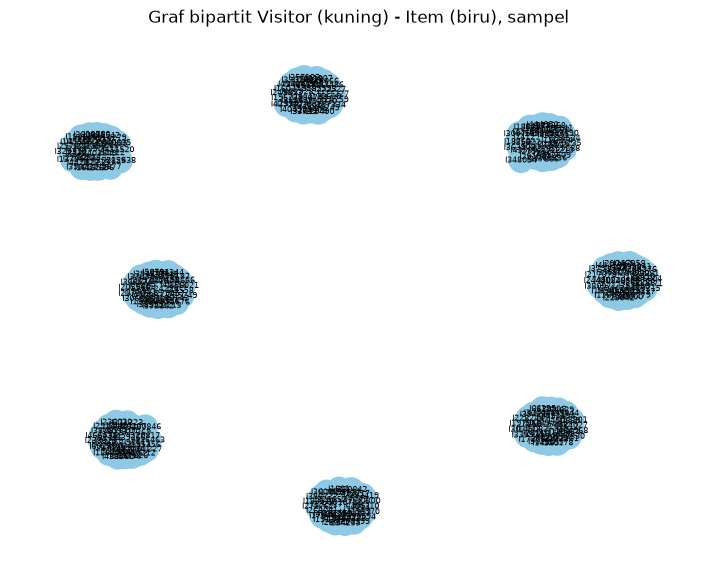

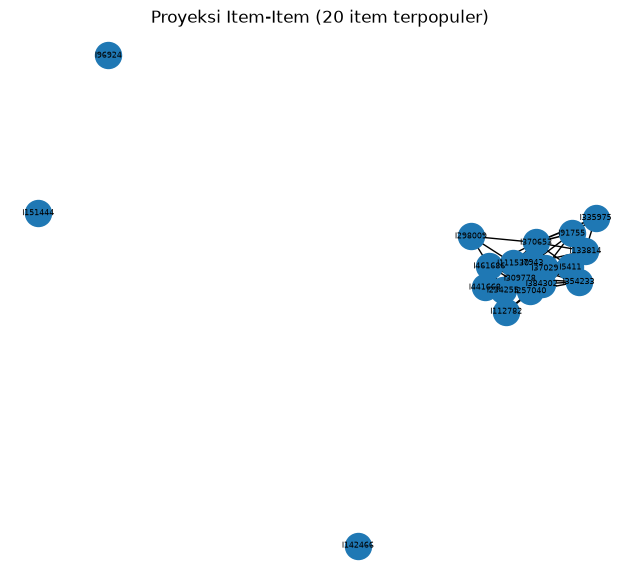

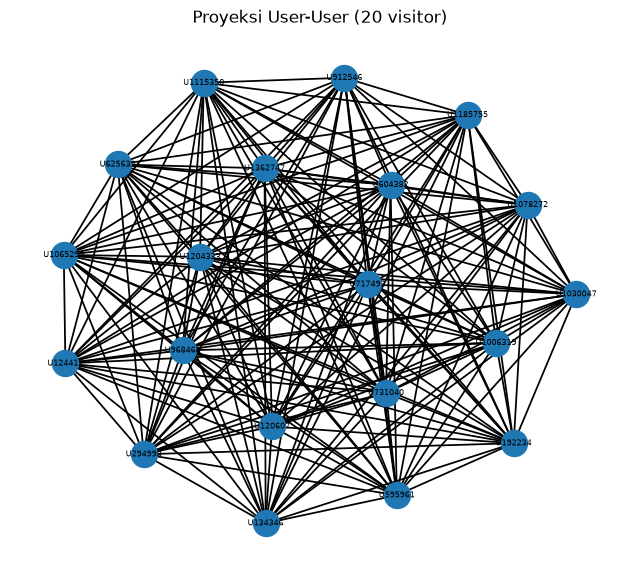

In [7]:
# plot networkx 1: graf bipartit Visitor-Item (sampel)
sel = np.where((deg >= 3) & (deg <= 30))[0]; sel = sel[np.argsort(-deg[sel])][:8]
G = nx.Graph([(f"U{users[a]}", f"I{items[b]}") for a in sel for b in X[a].indices])
plt.figure(figsize=(9, 7))
nx.draw_networkx(G, nx.spring_layout(G, seed=42), node_size=300, font_size=6,
                 node_color=["#ffb703" if n.startswith("U") else "#8ecae6" for n in G])
plt.title("Graf bipartit Visitor (kuning) - Item (biru), sampel"); plt.axis("off"); plt.show()

# plot networkx 2 & 3: proyeksi
def plot_proj(B, labels, title):
    C = (B @ B.T).tocoo(); G = nx.Graph(); G.add_nodes_from(labels)
    for a, b, v in zip(C.row, C.col, C.data):
        if a < b: G.add_edge(labels[a], labels[b], w=v)
    mx = max(1, C.data.max()) if C.nnz else 1
    w = [1 + 4*G[a][b]["w"]/mx for a, b in G.edges]
    plt.figure(figsize=(8, 7)); nx.draw_networkx(G, nx.spring_layout(G, seed=42), node_size=350, font_size=6, width=w)
    plt.title(title); plt.axis("off"); plt.show()

pop = np.argsort(-np.diff(Xi.indptr))[:20]
plot_proj((Xi[pop] > 0).astype(np.float32).tocsr(), [f"I{items[j]}" for j in pop], "Proyeksi Item-Item (20 item terpopuler)")
us = np.random.default_rng(42).choice(Xi[pop[0]].indices, min(20, len(Xi[pop[0]].indices)), replace=False)
plot_proj((X[us] > 0).astype(np.float32).tocsr(), [f"U{users[a]}" for a in us], "Proyeksi User-User (20 visitor)")

# Karakteristik VSM

| | VSM User | VSM Item |
|---|---|---|
| Shape | (872.547 x 190.170) | (190.170 x 872.547) |
| Dimensi (kolom) | 190.170 (item) | 872.547 (visitor) |
| Nilai tak nol (nnz) | 1.310.186 | 1.310.186 |
| Densitas | 7,90e-06 | 7,90e-06 |
| Sparsitas | 99,9992% | 99,9992% |
| Rata-rata nnz per baris | 1,50 item/visitor | 6,89 visitor/item |
| Maksimum nnz per baris | 485 | 1.670 |

**Interpretasi:**
- Kedua matriks **sangat sparse** (lebih dari 99,999% kosong), sehingga disimpan dalam format CSR.
- Rata-rata visitor hanya berinteraksi dengan 1,5 item (*cold-start* dan *long-tail*), sedangkan satu item rata-rata dilihat 6,89 visitor.
- 20 visitor bot (lebih dari 500 item) dibuang. Akibatnya jumlah visitor di VSM (872.547) sedikit lebih kecil dari di graf (872.567), dan item yang hanya disentuh bot ikut hilang (190.170 dari 191.300).

**Plot networkx:**
- *Graf bipartit* (sampel 8 visitor aktif): visitor (kuning) hanya terhubung ke item (biru), tidak ada garis antar-simpul sejenis.
- *Proyeksi item-item* (20 item terpopuler): dua item terhubung jika pernah dilihat visitor yang sama; ketebalan garis menunjukkan jumlah visitor bersama.
- *Proyeksi user-user* (20 visitor yang melihat item terpopuler): dua visitor terhubung jika berbagi minimal satu item.

# Pemilihan proyeksi

**Proyeksi yang lebih baik (efektif dan efisien)**

Jumlah sisi proyeksi `A @ A.T` ditaksir dengan **sampling 500 baris** (mengalikan baris sampel dengan seluruh matriks, lalu diskalakan ke seluruh baris), karena menghitung proyeksi penuh terlalu berat. Memori ditaksir 12 byte per sisi (indeks + nilai).

# Bandingkan proyeksi

In [8]:
def est_edges(A, sample=500):
    B = (A > 0).astype(np.float32).tocsr()
    idx = np.random.default_rng(0).choice(A.shape[0], min(sample, A.shape[0]), replace=False)
    return (B[idx] @ B.T).nnz / len(idx) * A.shape[0]

for nm, A in [("user-user", X), ("item-item", Xi)]:
    e = est_edges(A)
    print(f"Proyeksi {nm}: simpul={A.shape[0]:,} | taksiran sisi={e:,.0f} | taksiran memori~{e*12/1e9:.2f} GB")

Proyeksi user-user: simpul=872,547 | taksiran sisi=83,068,219 | taksiran memori~1.00 GB
Proyeksi item-item: simpul=190,170 | taksiran sisi=10,851,481 | taksiran memori~0.13 GB


# Kesimpulan proyeksi

| Proyeksi | Simpul | Taksiran sisi | Taksiran memori |
|---|---|---|---|
| User-User | 872.547 | ± 83.068.219 | ± 1,00 GB |
| Item-Item | 190.170 | ± 10.851.481 | ± 0,13 GB |

**Kesimpulan: proyeksi Item-Item lebih baik (efektif dan efisien)**, dengan alasan:
1. **Efisiensi:** jumlah item jauh lebih sedikit daripada visitor (±4,6x), sehingga simpul, sisi (±7,7x lebih sedikit), dan memorinya jauh lebih kecil. Proyeksi user-user nyaris tidak terkelola untuk seluruh data.
2. **Efektivitas:** satu item dilihat banyak visitor (rata-rata 6,89, maksimum 1.670), sedangkan sebagian besar visitor hanya punya 1-2 interaksi. Kemiripan antar-item dihitung dari bukti yang lebih banyak, sehingga lebih stabil daripada kemiripan antar-visitor.
3. **Skalabilitas:** kemiripan item relatif stabil dan bisa dipakai ulang untuk merekomendasikan item ke semua visitor, termasuk visitor baru yang punya sedikit riwayat.

Karena itu similarity (No. 7) dan rekomendasi KNN (2.2) dilakukan pada proyeksi **item-item**.

# Similarity

**Perhitungan similarity pada graf terproyeksi**

**Metode:** *cosine similarity* antar vektor item pada VSM Item:

$$\cos(a,b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

Nilainya 0 sampai 1. Dua item mirip jika dilihat atau dibeli oleh visitor yang sama.

**Kaitan dengan graf terproyeksi:** proyeksi item-item adalah matriks `Xi · Xiᵀ` (bobot sisi = interaksi visitor bersama). Cosine similarity pada VSM Item setara dengan menormalkan bobot sisi proyeksi tersebut (dibagi norma kedua item), sehingga ini adalah perhitungan similarity pada graf proyeksi item-item.

**Optimasi:** kemiripan dihitung per *chunk* (1.000 item) dan hanya **20 tetangga terdekat** tiap item yang disimpan (top-k). Item yang dilihat kurang dari 3 visitor diabaikan karena kemiripannya semu (bisa bernilai 1,0 hanya dari satu visitor yang sama). Hasilnya disimpan sebagai relasi berarah `(:Item)-[:SIMILAR_TO {score}]->(:Item)` di Neo4j.

# Hitung similarity

In [9]:
def topk_cosine(M, k=20, chunk=1000):
    n = M.shape[0]
    Mn = normalize(M, axis=1).astype(np.float32).tocsr(); MT = Mn.T.tocsc()
    R, C, V = [], [], []
    for s in range(0, n, chunk):
        S_ = (Mn[s:s+chunk] @ MT).tocsr()
        for r in range(S_.shape[0]):
            a, b = S_.indptr[r], S_.indptr[r+1]
            idx, v = S_.indices[a:b], S_.data[a:b]
            m = idx != s + r; idx, v = idx[m], v[m]          # buang diri sendiri
            if len(v) == 0: continue
            if len(v) > k:
                t = np.argpartition(-v, k-1)[:k]; idx, v = idx[t], v[t]
            R += [s+r]*len(v); C += idx.tolist(); V += v.tolist()
        if (s // chunk) % 20 == 0: print(f"{min(s+chunk, n):,} / {n:,} item")
    return sp.csr_matrix((V, (R, C)), shape=(n, n), dtype=np.float32)

support = np.asarray((X > 0).sum(axis=0)).ravel()                 # jumlah visitor per item
M = sp.diags((support >= 3).astype(np.float32)) @ Xi              # abaikan item yang dilihat < 3 visitor
S = topk_cosine(M.tocsr(), k=20)
print("Sisi similarity:", S.nnz)

1,000 / 190,170 item
21,000 / 190,170 item
41,000 / 190,170 item
61,000 / 190,170 item
81,000 / 190,170 item
101,000 / 190,170 item
121,000 / 190,170 item
141,000 / 190,170 item
161,000 / 190,170 item
181,000 / 190,170 item
Sisi similarity: 867874


# Tulis similarity ke Neo4j

In [19]:
coo = S.tocoo()
rows = [{"a": int(items[a]), "b": int(items[b]), "score": float(v)} for a, b, v in zip(coo.row, coo.col, coo.data)]
q_sim = """UNWIND $rows AS row
MATCH (a:Item {itemId: row.a}) MATCH (b:Item {itemId: row.b})
MERGE (a)-[r:SIMILAR_TO]->(b) SET r.score = row.score, r.method = 'cosine'"""
with driver.session() as s:
    for k in range(0, len(rows), 5000):
        write(s, run, q_sim, rows=rows[k:k+5000])
print("SIMILAR_TO selesai ditulis:", len(rows))

SIMILAR_TO selesai ditulis: 867874


# No. 7a dan 7b

### 7(a) Cypher untuk 5 record dengan similarity tertinggi

**Record acuan:** item terpopuler (dilihat paling banyak visitor) yang punya minimal 5 tetangga, supaya hasilnya bermakna.

```cypher
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY s.score DESC LIMIT 5
```

`MATCH` menelusuri relasi `SIMILAR_TO` keluar dari item acuan; `ORDER BY ... DESC LIMIT 5` mengambil lima nilai tertinggi.

### 7(b) Menuliskan kembali nilai similarity ke graf

Nilai similarity ditulis sebagai properti relasi (sel penulisan di atas):

```cypher
MERGE (a)-[r:SIMILAR_TO]->(b) SET r.score = row.score, r.method = 'cosine'
```

`MERGE` mencegah relasi ganda; `SET` menyimpan nilai `score`. Query pada 7(a) membaca kembali nilai dari graf, sehingga membuktikan nilainya telah tersimpan.

# Top-5 similarity

In [20]:
nb = np.diff(S.indptr)
ref = int(items[next(j for j in np.argsort(-support) if nb[j] >= 5)])   # item acuan
print("Item acuan (record acuan) =", ref)

q_top5 = """MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY s.score DESC LIMIT 5"""
with driver.session() as s:
    hasil = pd.DataFrame(s.run(q_top5, ref=ref).data())
hasil

Item acuan (record acuan) = 5411


,acuan,item_mirip,similarity
0,5411,33030,0.152771
1,5411,33956,0.093301
2,5411,37807,0.085489
3,5411,358234,0.078387
4,5411,459936,0.076788


# Hasil top-5

**Hasil (item acuan = 5411):**

| Peringkat | Item mirip | Similarity |
|---|---|---|
| 1 | 33030 | 0,1528 |
| 2 | 33956 | 0,0933 |
| 3 | 37807 | 0,0855 |
| 4 | 358234 | 0,0784 |
| 5 | 459936 | 0,0768 |

Nilai similarity relatif kecil karena data sangat sparse (rata-rata visitor hanya melihat 1,5 item), sehingga irisan visitor antar-item sedikit. Meski begitu, urutan peringkatnya tetap bermakna untuk rekomendasi.

# No. 8

**Kondisi graf sebelum dan sesudah perhitungan similarity**

Cypher untuk membandingkan komposisi graf:

```cypher
MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah;
MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah;
```

# Sebelum dan sesudah

In [21]:
nodes1, rels1 = snapshot()
print("=== SEBELUM similarity ===\n", nodes0, "\n", rels0)
print("\n=== SESUDAH similarity ===\n", nodes1, "\n", rels1)
print("\nItem acuan untuk visualisasi:", ref)

=== SEBELUM similarity ===
   jenis_simpul  jumlah
0      Visitor  872567
1         Item  191300 
     jenis_relasi   jumlah
0         VIEWED  1657632
1  ADDED_TO_CART    41888
2         BOUGHT    13773

=== SESUDAH similarity ===
   jenis_simpul  jumlah
0      Visitor  872567
1         Item  191300 
     jenis_relasi   jumlah
0         VIEWED  1657632
1     SIMILAR_TO   867874
2  ADDED_TO_CART    41888
3         BOUGHT    13773

Item acuan untuk visualisasi: 5411


# Hasil dan screenshot graf

### Hasil

| Komponen | Sebelum | Sesudah |
|---|---|---|
| Simpul Visitor | 872.567 | 872.567 |
| Simpul Item | 191.300 | 191.300 |
| Relasi VIEWED | 1.657.632 | 1.657.632 |
| Relasi ADDED_TO_CART | 41.888 | 41.888 |
| Relasi BOUGHT | 13.773 | 13.773 |
| **Relasi SIMILAR_TO** | **tidak ada** | **867.874** |

Jumlah simpul tidak berubah. Perubahan hanya berupa **satu jenis relasi baru, `SIMILAR_TO`**, yang menghubungkan item dengan item lain (top-20 tetangga) beserta nilai `score`.

### Visualisasi graf (Neo4j Query), item acuan 5411

**Sebelum** (item acuan dan visitor yang berinteraksi, belum ada `SIMILAR_TO`):

```cypher
MATCH p=(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: 5411})
RETURN p LIMIT 25;
```

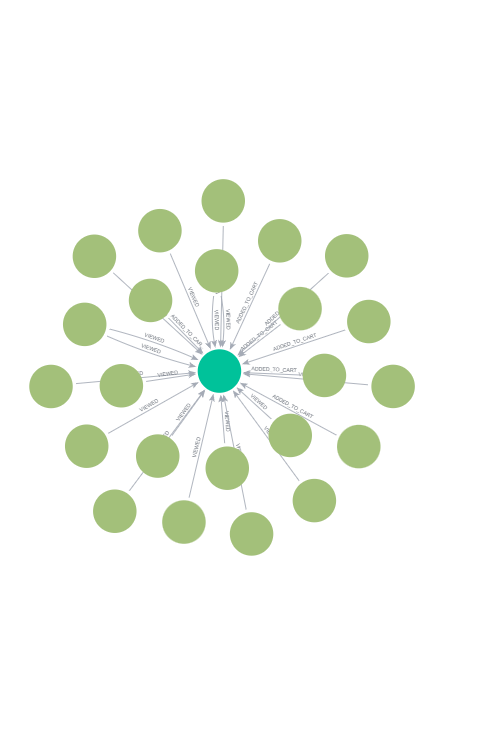

**Sesudah** (item acuan dengan 5 item termirip lewat relasi `SIMILAR_TO`, nilai `score` pada relasi):

```cypher
MATCH p=(a:Item {itemId: 5411})-[s:SIMILAR_TO]->(b:Item)
WITH p, s ORDER BY s.score DESC LIMIT 5
RETURN p;
```

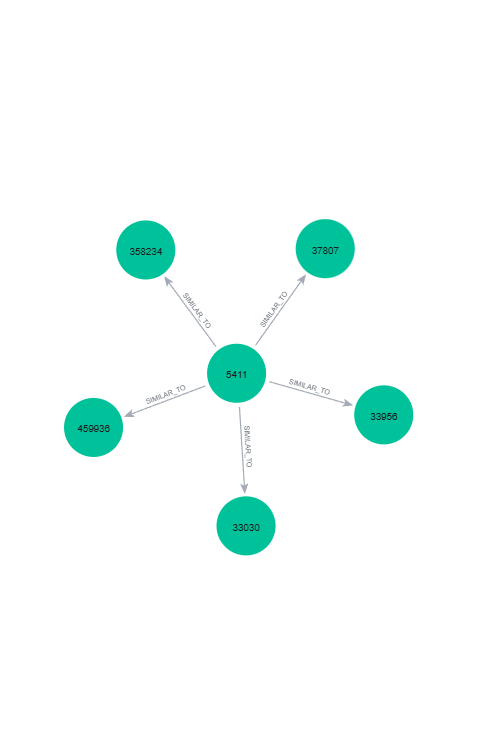

# Analytics


**1(a) Pemilihan user acak (reproducible)**

Kandidat user: visitor yang **ada di fold training (minimal 2 item)** dan **punya item relevan di fold testing**. Daftar kandidat diurutkan, lalu dipilih satu dengan `np.random.default_rng(seed=NIM).choice(...)`, sehingga hasilnya selalu sama setiap dijalankan.

**Kunci jawaban (item relevan):** item yang di-*addtocart* atau dibeli user di fold testing.

### Algoritma KNN item-based (k = 5)
1. Untuk setiap item `h` pada riwayat training user (bobot `w_h`), ambil **5 tetangga terdekat** (similarity tertinggi) dari graf `SIMILAR_TO`.
2. Skor kandidat `j` = jumlah dari `w_h x sim(h, j)` atas semua item riwayat.
3. Item yang sudah pernah disentuh user dibuang.
4. Urutkan skor menurun; **top-5** adalah rekomendasi, dan **3 teratas adalah item yang diiklankan** (1b).

# Rekomendasi KNN

In [13]:
def recommend_item_knn(u, k=5, topn=5):
    row = X[u]; sc = {}
    for h, wh in zip(row.indices, row.data):
        a, b = S.indptr[h], S.indptr[h+1]
        nb_, sv = S.indices[a:b], S.data[a:b]
        if len(sv) > k:
            t = np.argsort(-sv)[:k]; nb_, sv = nb_[t], sv[t]       # k tetangga terdekat
        for j, s_ in zip(nb_, sv): sc[j] = sc.get(j, 0) + float(wh) * float(s_)
    for h in row.indices: sc.pop(h, None)                          # buang item yang sudah pernah
    return sorted(sc.items(), key=lambda t: -t[1])[:topn]

# kunci jawaban: item yang di-addtocart / dibeli user di fold TESTING
gt = test[test.event.isin(["addtocart", "transaction"])].groupby("visitorid").itemid.apply(set).to_dict()
uidx = {int(v): n for n, v in enumerate(users)}
cand = sorted(v for v in gt if v in uidx and deg[uidx[v]] >= 2)    # user ada di train dan test

rng = np.random.default_rng(int(NIM))                              # seed = NIM, bisa direproduksi
target = int(rng.choice(cand))
rel = {int(x) for x in gt[target]}
recs = [(int(items[j]), s_) for j, s_ in recommend_item_knn(uidx[target], k=5)]
ids = [x for x, _ in recs]

print("Jumlah kandidat user:", len(cand), "| user terpilih:", target)
print("Item relevan di fold testing:", rel, "\n")
for r, (it, sc_) in enumerate(recs, 1):
    print(f"{r}. item {it} | skor {sc_:.4f}", "<-- DIIKLANKAN" if r <= 3 else "", "[HIT]" if it in rel else "")

Jumlah kandidat user: 457 | user terpilih: 707544
Item relevan di fold testing: {135900} 

1. item 169864 | skor 0.1251 <-- DIIKLANKAN 
2. item 387373 | skor 0.1195 <-- DIIKLANKAN 
3. item 62895 | skor 0.1185 <-- DIIKLANKAN 
4. item 245721 | skor 0.1134  
5. item 359652 | skor 0.1103  


# No. 1b

**1(b) Hasil rekomendasi untuk k = 5**

- Jumlah kandidat user: **457**
- Proses acak: `np.random.default_rng(seed=23031554066)`
- **User terpilih:** `visitorId = 707544`
- **Item relevan di fold testing:** {135900}

| Peringkat | Item | Skor | Keterangan |
|---|---|---|---|
| 1 | 169864 | 0,1251 | **Diiklankan** |
| 2 | 387373 | 0,1195 | **Diiklankan** |
| 3 | 62895 | 0,1185 | **Diiklankan** |
| 4 | 245721 | 0,1134 | |
| 5 | 359652 | 0,1103 | |

**3 item yang diiklankan: 169864, 387373, dan 62895.**

# Metrik

Misal `rel` = himpunan item relevan dan `rec` = daftar rekomendasi.

- **Hit@5** = 1 jika minimal satu item relevan ada di 5 rekomendasi teratas, dan 0 jika tidak.
- **NDCG@5** = DCG / IDCG, dengan

$$DCG@5 = \sum_{i=1}^{5} \frac{rel_i}{\log_2(i+1)}, \qquad IDCG@5 = \sum_{i=1}^{\min(|rel|,5)} \frac{1}{\log_2(i+1)}$$

`rel_i` = 1 jika item di peringkat ke-i relevan. Item benar di peringkat atas bernilai lebih besar. IDCG adalah DCG ideal (semua item relevan berada di peringkat teratas).

# Hitung metrik

In [14]:
def hit_at_k(rec, rel, k=5): return int(any(x in rel for x in rec[:k]))
def ndcg_at_k(rec, rel, k=5):
    dcg  = sum(1/math.log2(r+2) for r, x in enumerate(rec[:k]) if x in rel)
    idcg = sum(1/math.log2(r+2) for r in range(min(len(rel), k)))
    return dcg/idcg if idcg else 0.0

print("Hit@5  =", hit_at_k(ids, rel))
print("NDCG@5 =", round(ndcg_at_k(ids, rel), 4))

Hit@5  = 0
NDCG@5 = 0.0


# Diagnosis hasil

In [15]:
hist_items = [int(items[j]) for j in X[uidx[target]].indices]
print("Riwayat item training user :", hist_items)
print("Item relevan (testing)     :", rel)
print("Item relevan ada di daftar item training?", [i in set(map(int, items)) for i in rel])

Riwayat item training user : [52301, 426351, 463280]
Item relevan (testing)     : {135900}
Item relevan ada di daftar item training? [True]


In [22]:
j = int(np.where(items == next(iter(rel)))[0][0])
print("Jumlah visitor training yang melihat item relevan:", int(support[j]))
print("Jumlah tetangga SIMILAR_TO item relevan          :", int(np.diff(S.indptr)[j]))
print("Item relevan masuk 'support >= 3'?               :", bool(support[j] >= 3))

Jumlah visitor training yang melihat item relevan: 201
Jumlah tetangga SIMILAR_TO item relevan          : 20
Item relevan masuk 'support >= 3'?               : True


In [23]:
for h in X[uidx[target]].indices:
    a, b = S.indptr[h], S.indptr[h+1]
    nb_ = [int(items[x]) for x in S.indices[a:b]]
    print(f"Item riwayat {int(items[h])}: {b-a} tetangga | 135900 ada di tetangga? {next(iter(rel)) in nb_}")

Item riwayat 52301: 20 tetangga | 135900 ada di tetangga? False
Item riwayat 426351: 20 tetangga | 135900 ada di tetangga? False
Item riwayat 463280: 20 tetangga | 135900 ada di tetangga? False


# Evaluasi 100 user acak

In [16]:
# konteks: rata-rata untuk 100 user acak (seed sama, reproducible)
sample = np.random.default_rng(int(NIM)).choice(cand, 100, replace=False)
H, N = [], []
for v in sample:
    r_ = [int(items[j]) for j, _ in recommend_item_knn(uidx[int(v)], k=5)]
    g_ = {int(x) for x in gt[int(v)]}
    H.append(hit_at_k(r_, g_)); N.append(ndcg_at_k(r_, g_))
print("Rata-rata 100 user -> Hit@5:", np.mean(H), "| NDCG@5:", round(np.mean(N), 4))

Rata-rata 100 user -> Hit@5: 0.01 | NDCG@5: 0.0024


# Hasil evaluasi dan kesimpulan

| Metrik | User terpilih (707544) | Rata-rata 100 user acak |
|---|---|---|
| Hit@5 | **0** | 0,01 |
| NDCG@5 | **0,0** | 0,0024 |

**Perhitungan untuk user 707544:** satu-satunya item relevan adalah 135900, sedangkan top-5 rekomendasi adalah 169864, 387373, 62895, 245721, 359652. Tidak ada item relevan di top-5, sehingga DCG = 0, Hit@5 = 0, dan NDCG@5 = 0 / (1/log2(2)) = 0.

**Mengapa hasilnya rendah?**
1. **Data sangat sparse.** Rata-rata visitor hanya berinteraksi dengan 1,5 item (sparsitas 99,9992%), sehingga sinyal kemiripan terbatas.
2. **Kunci jawaban ketat.** Item relevan hanya item yang di-addtocart atau dibeli di fold testing (user terpilih hanya punya 1 item relevan), sedangkan ruang pilihan mencapai 190.170 item.
3. **Evaluasi satu user tidak stabil.** Hasil 0 tidak otomatis berarti model gagal. Rata-rata 100 user (Hit@5 = 0,01, yaitu 1 dari 100 user) tetap rendah. Dengan sampel sekecil itu, satu hit mengubah angka, jadi nilainya hanya gambaran kasar dan bukan bukti kuat tentang kualitas model.
4. **Item relevan tidak masuk tetangga terdekat.** Untuk user 707544, item 135900 dilihat oleh 201 visitor dan punya 20 tetangga `SIMILAR_TO`, sehingga ikut dalam perhitungan similarity. Namun item ini tidak termasuk 5 tetangga terdekat dari item-item riwayat user (52301, 426351, 463280), sehingga tidak masuk top-5 (lihat sel diagnosis). Artinya kegagalan pada user ini disebabkan oleh pola kemiripan item riwayatnya, bukan karena item relevan tidak terjangkau oleh model.

**Kemungkinan perbaikan:** menggabungkan item populer sebagai *fallback*, memakai user-based KNN sebagai pembanding, atau memperluas definisi item relevan.

## Kesimpulan

1. Data RetailRocket periode 09/05-28/07/2015 (training) dan 29/07-18/08/2015 (testing) dimodelkan sebagai graf bipartit berarah Visitor -> Item di Neo4j (872.567 Visitor, 191.300 Item, 1.713.293 relasi).
2. VSM user dan item bersifat sangat sparse (> 99,999%). Proyeksi **item-item** lebih efisien (± 10,9 juta sisi vs ± 83 juta sisi pada user-user).
3. Cosine similarity antar-item (top-20) disimpan sebagai relasi `SIMILAR_TO` (867.874 relasi) tanpa mengubah simpul.
4. Rekomendasi KNN item-based (k = 5) untuk user 707544 menghasilkan tiga item iklan: 169864, 387373, 62895, dengan Hit@5 = 0 dan NDCG@5 = 0 (rata-rata 100 user: Hit@5 = 0,01; NDCG@5 = 0,0024).
5. Rendahnya Hit@5 dan NDCG@5 sangat dipengaruhi oleh sparsitas data (rata-rata 1,5 item per visitor) dan kunci jawaban yang ketat. Evaluasi pada sampel kecil hanya memberi gambaran kasar, sehingga perbandingan dengan metode lain (misalnya user-based KNN atau fallback item populer) diperlukan untuk menilai kualitas model.